In [41]:
%load_ext autoreload
%autoreload 
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:

from pandas.core.common import flatten
import matplotlib

In [53]:
import nltk

In [25]:
from __future__ import print_function
import ruamel.yaml as ry
import pandas as pd

In [26]:
import os
import sys
sys.path.append('../')

In [27]:
from src.data.make_dataset import DataProcessing, DataToAzure

In [28]:
config_file = "/home/ml/Documents/BI_Help/config/config.yml"

In [29]:
def build_configuration(config_file):
    """
    Build the operation configuration dict
    :param config_file: is the path to the yaml config_file
    :type: string
    :return: config: global configuration
    :rtype dict
    """
    # yaml config
    
    with open(config_file, 'r') as stream:
        try:
            return ry.safe_load(stream)
        except ry.YAMLError as exc:
            print(exc)

In [30]:
config = build_configuration(config_file)

In [31]:
obj_df_loaded = DataProcessing(config)

In [32]:
df_cleaned = obj_df_loaded.data_cleaned()

b'Skipping line 2189: expected 367 fields, saw 369\n'
b'Skipping line 27321: expected 367 fields, saw 369\nSkipping line 27322: expected 367 fields, saw 369\n'


### Visualisation 

In [33]:
df_cleaned

,corrected_code,category,text_grouped,text_grouped_flatten,text
0,01100,séminaire congrès convention presta hotelière ...,"[[PRESTATION, TRAITEUR, POUR, 2012], [Speakerw...","[prestation, traiteur, speakerwise, forum, avs...","[prestation, traiteur, speakerwise, forum, avs..."
1,01200,Frais d'inscription aux foires et expositions ...,"[[COMP, AFF, MONITEUR, TUBE, M12-120GY], [ECRO...","[comp, aff, moniteur, tube, m gy, ecrou, dissi...","[comp, aff, moniteur, tube, m, gy, ecrou, diss..."
2,01300,Prestations annexes aux foires et expositions ...,"[[Screenshot], [Fourniture, bo, tier, TOP, AXY...","[screenshot, fourniture, tier, top, axyz, acom...","[screenshot, fourniture, tier, top, axyz, acom..."
3,013002TAV,Electricité ...,[[test]],[test],[test]
4,01300A,TGS Participation Salon ...,"[[Salons, TGS, 2016], [2018, Exhibitions, Even...","[salons, tgs, exhibitions, events, test]","[salon, tgs, exhibition, event, test]"
...,...,...,...,...,...
222,92001,moyens de production de front end et de back e...,"[[Contr, le, metrologique, table, EVO, 10], [C...","[contr, metrologique, table, evo, contr, metro...","[contr, metrologiqu, table, evo, contr, metrol..."
223,92040,Maintenance de moyens de production front end ...,"[[pieces, detachees, Qualmark], [EXCAL, 1421, ...","[pieces, detachees, qualmark, excal, contr, ve...","[piece, detachees, qualmark, excal, contr, ver..."
224,95100,équipements aéronautiques ...,"[[STANDBY, CONTROL, PANEL], [VHF, TRANCEIVER, ...","[standby, control, panel, vhf, tranceiver, khz...","[standby, control, panel, vhf, tranceiver, khz..."
225,9510010,Groupe 95100 classe valo. 8010 ...,"[[Keyboard, (KBD), MFD5x4, (E24273BA)], [Displ...","[keyboard, kbd , mfdx, eba , display, head, ...","[keyboard, , kbd, , mfd, , eba, , display,..."


In [46]:
df_cleaned['occurence_words'] = df_cleaned['text'].apply(lambda x : len(x))
df_cleaned['occurence_code'] = df_cleaned['text_grouped'].apply(lambda x : len(x))

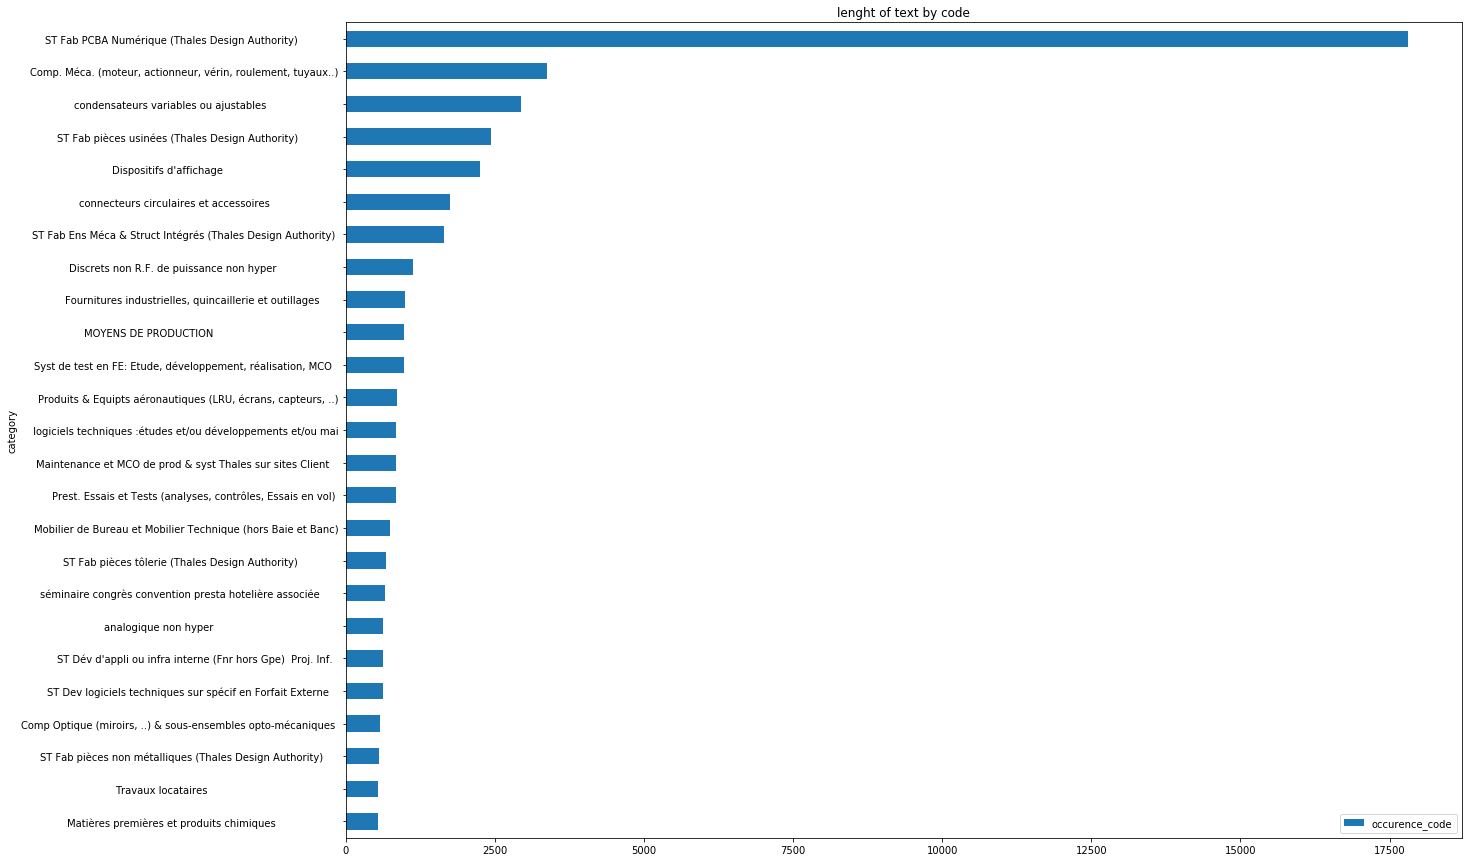

In [49]:
df_cleaned[df_cleaned['occurence_code'] > 500].sort_values('occurence_code', ascending = True).plot.barh(x='category', y='occurence_code', figsize = (20,15), title='lenght of text by code')

In [61]:

from nltk import FreqDist

In [99]:
def plot_words_frequency(code):
    import matplotlib.pyplot as plt
    plt.figure(figsize=(30, 15))  # the size you want
    df = df_cleaned[df_cleaned['corrected_code'] == code]
    fdist = FreqDist(list(df['text'])[0])
    fdist.plot(100, cumulative=False, title = 'code : ' + code)

In [100]:
list_of_code = list(df_cleaned['corrected_code'].unique())

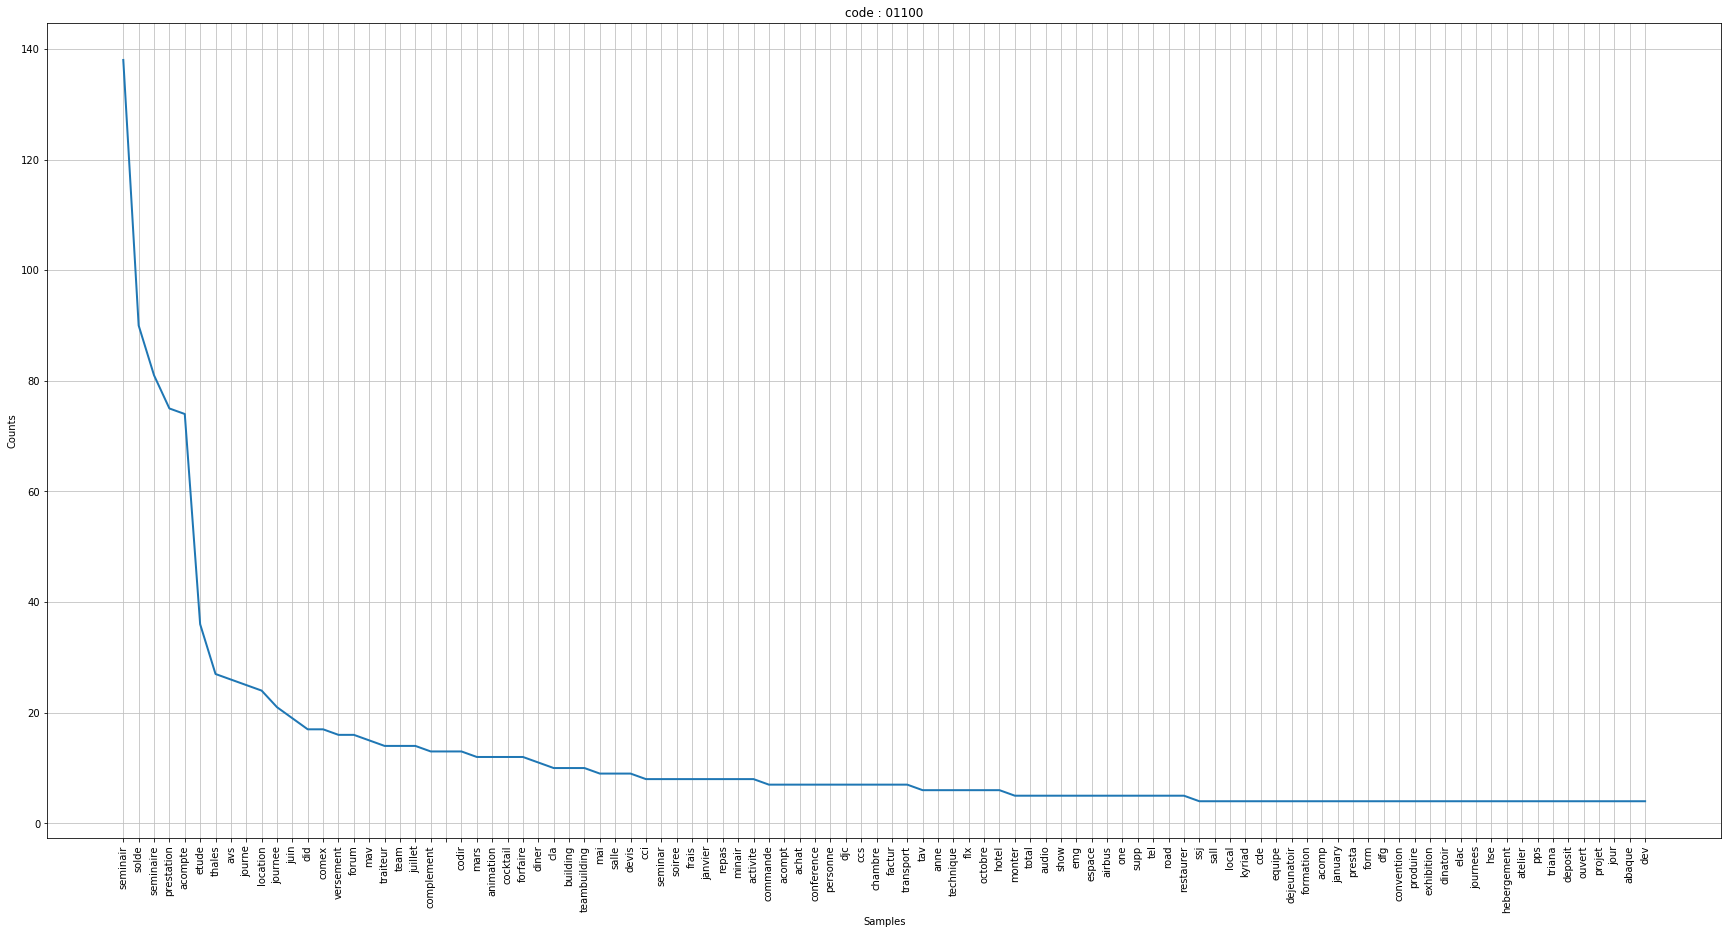

In [102]:
plot_words_frequency(list_of_code[0])

In [95]:
from wordcloud import WordCloud

In [ ]:
wordcloud = WordCloud().generate(text)


In [ ]:
wordcloud = WordCloud(max_font_size=40).generate(text)
plt.figure(figsize =(30,20))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [187]:
def plot_words_cloud(code):
    import matplotlib.pyplot as plt
   
    plt.figure(figsize=(20, 10))  # the size you want
    df = df_cleaned[df_cleaned['corrected_code'] == code]
    text = ' '.join(list(df['text'])[0])
    wordcloud = WordCloud(max_font_size=40,  background_color="white").generate(text)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.title('code : ' + code + '\n' + ' descriptif du code : '  + df.category.values[0])
    plt.axis("off")
    plt.show()
  

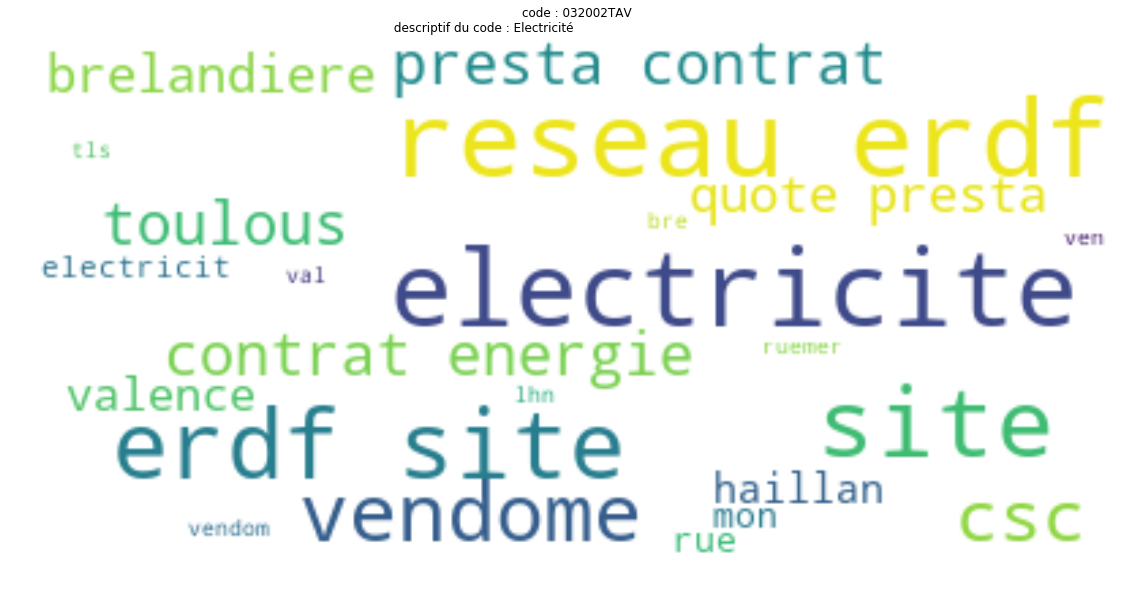

In [194]:
plot_words_cloud(list_of_code[22])